<a href="https://colab.research.google.com/github/rohanchorge979-max/movie-review-sentiment-analyzer/blob/main/nlp_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets gradio scikit-learn accelerate

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Baseline  Acc: 0.843  F1: 0.8428428428428428


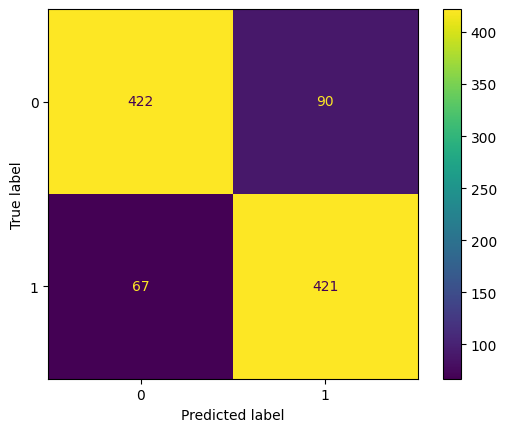

In [ ]:
from datasets import load_dataset
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

ds = load_dataset("stanfordnlp/imdb")
train = ds["train"].shuffle(seed=42).select(range(4000))
test = ds["test"].shuffle(seed=42).select(range(1000))

def clean(t):
    t = re.sub(r"<.*?>", " ", t.lower())
    return re.sub(r"[^a-z\s]", " ", t)

Xtr = [clean(t) for t in train["text"]]
Xte = [clean(t) for t in test["text"]]

vec = TfidfVectorizer(stop_words="english", max_features=20000)
lr = LogisticRegression(max_iter=1000).fit(vec.fit_transform(Xtr), train["label"])
pred = lr.predict(vec.transform(Xte))

base_acc = accuracy_score(test["label"], pred)
base_f1 = f1_score(test["label"], pred)
print("Baseline  Acc:", base_acc, " F1:", base_f1)
ConfusionMatrixDisplay(confusion_matrix(test["label"], pred)).plot()

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss


DistilBERT  Acc: 0.832  F1: 0.8285714285714286


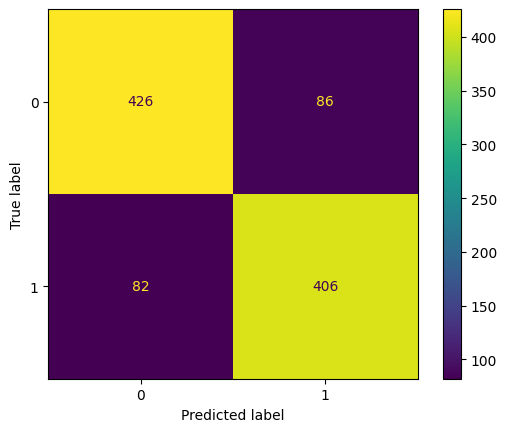

In [ ]:
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments

name = "distilbert-base-uncased"
tok = AutoTokenizer.from_pretrained(name)
enc = lambda b: tok(b["text"], truncation=True, padding="max_length", max_length=128)
tr = train.map(enc, batched=True)
te = test.map(enc, batched=True)

model = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2)
args = TrainingArguments(output_dir="out", num_train_epochs=1,
                         per_device_train_batch_size=16, per_device_eval_batch_size=32,
                         report_to="none", save_strategy="no")
trainer = Trainer(model=model, args=args, train_dataset=tr)
trainer.train()

out = trainer.predict(te)
bp = np.argmax(out.predictions, axis=1)
bert_acc = accuracy_score(test["label"], bp)
bert_f1 = f1_score(test["label"], bp)
print("DistilBERT  Acc:", bert_acc, " F1:", bert_f1)
ConfusionMatrixDisplay(confusion_matrix(test["label"], bp)).plot()

In [ ]:
import pandas as pd
pd.DataFrame({"Model": ["TF-IDF + LogReg", "DistilBERT"],
              "Accuracy": [base_acc, bert_acc],
              "F1": [base_f1, bert_f1]})

,Model,Accuracy,F1
0,TF-IDF + LogReg,0.843,0.842843
1,DistilBERT,0.832,0.828571


In [ ]:
import gradio as gr, torch

def predict(text):
    inputs = tok(text, return_tensors="pt", truncation=True, max_length=128).to(model.device)
    with torch.no_grad():
        p = torch.softmax(model(**inputs).logits, dim=-1)[0]
    return {"Negative": float(p[0]), "Positive": float(p[1])}

gr.Interface(fn=predict,
             inputs=gr.Textbox(lines=4, placeholder="Type a movie review..."),
             outputs=gr.Label(num_top_classes=2),
             title="Movie Review Sentiment Analyzer").launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://444e6bb7a9b278530b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
